### 工作進度  
* 【置頂】**筆記內容架構**與**量化技術分析系統**相關資訊請參閱[260531筆記.ipynb](https://github.com/yilintung/StockInvestmentNotebook/blob/main/260531%E7%AD%86%E8%A8%98.ipynb)之「工作進度」。  
* 發現「股票解盤」StockAnalysis類別的「整體評價」內部方法問題，進行程式碼修改與驗證。  
  - 修改[StockAnalysis.py](https://github.com/yilintung/StockInvestmentNotebook/blob/main/mysys/StockAnalysis.py)程式碼：[Update StockAnalysis.py](https://github.com/yilintung/StockInvestmentNotebook/commit/8e078276c28ca1eaad8706cf18d7ef794aa35cbf)。  

* 引入模組與定義公用函式  

In [1]:
import numpy as np
import mysys
import markdown
from IPython.core.display import HTML

In [2]:
def stock_analysis( analysis, stock_id, buttom_pattern = False) :
    results,images = analysis.analysis(stock_id)
    if results is not None :
        if buttom_pattern is True and '底部型態' in images :
            print('底型反轉交易策略：')
            display(images['底部型態'])
        print('解盤內容：')
        if '整體評價' in images and images['整體評價'] is not None  :
            display(images['整體評價'])
        result_md   = results.to_markdown(tablefmt="grid")
        result_html = markdown.markdown(result_md, extensions=['markdown_grid_tables:GridTableExtension'])
        display(HTML(result_html))

* 建立「解盤」物件    

In [3]:
# 修改程式後的驗證，開啟「除錯模式」
analysis = mysys.StockAnalysis(debug=True)

* 驗證：加權指數   

ＤＥＢＵＧ ： 日Ｋ開始日期 ＝ 2024-11-25 ，日Ｋ結束日期 ＝ 2026-11-28 ， 週Ｋ開始日期 ＝ 2024-11-25 ， 週Ｋ結束日期 ＝ 2026-11-23
ＤＥＢＵＧ ： 日Ｋ價格資料總數＝ 488
ＤＥＢＵＧ ： 轉折點引數列表 ＝ [{'mode': 'open_close', 'order': 5}, {'mode': 'open_close', 'order': 10}, {'mode': 'close', 'order': 10, 'smoothing': 3}]
ＤＥＢＵＧ ： 轉折點資料確認範圍 （開始索引 ＝ 0 ，結束索引 ＝ 33） 
ＤＥＢＵＧ ： 轉折點資料確認範圍 （開始索引 ＝ 0 ，結束索引 ＝ 17） 
ＤＥＢＵＧ ： 轉折點資料確認範圍 （開始索引 ＝ 0 ，結束索引 ＝ 14） 
ＤＥＢＵＧ ： 轉折點引數列表 ＝ [{'mode': 'high_low', 'order': 5}, {'mode': 'open_close', 'order': 5}, {'mode': 'close', 'order': 10, 'smoothing': 3}, {'mode': 'close', 'order': 10, 'smoothing': 5}, {'mode': 'open_close', 'order': 10}, {'mode': 'open_close', 'order': 20}]
ＤＥＢＵＧ ： 由轉折點識別之可能型態列表 ： 
[['下降楔形', {'mode': 'high_low', 'order': 5},                 Date     Price Type
DateIndex                          
324       2026-10-06  49968.92   HI
344       2026-11-06  37837.05   LO
348       2026-11-12  44525.24   HI
355       2026-11-23  35442.41   LO], ['上升楔形', {'mode': 'close', 'order': 10, 'smoothing': 5},                 Dat

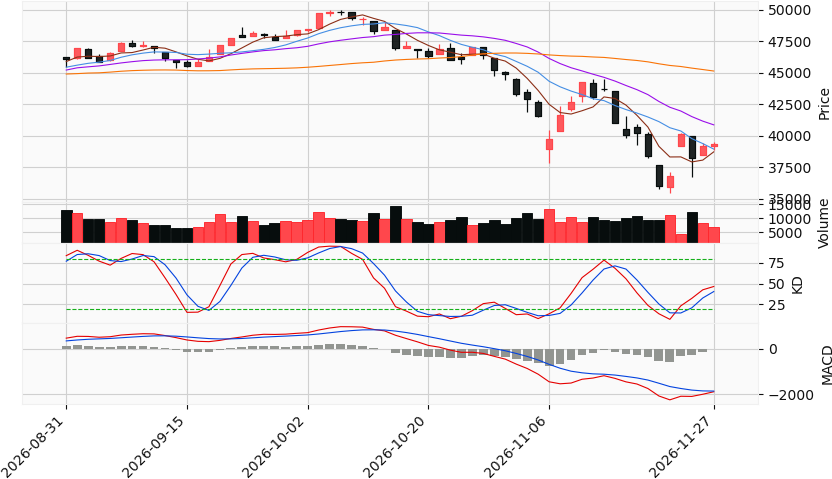

技術分析工具,解盤內容
Ｋ線／Ｋ棒,紡錘線 : 2026-11-27 十字線 : 2026-11-27 孕育線／懷抱線 : 2026-11-26
Ｋ線圖,中期為低位階 長期為中位階
成交量,價量關係：成交量小於十日均量（成交量 ＝ 6946.61億元 ，十日均量 ＝ 9185.52億元）
型態,反轉型態之下降楔形，型態範圍由2026-10-06開始到2026-11-26結束。
移動平均線,5日線上揚、10日線下彎，短期盤整；20日線下彎、60日線下彎，中期翻空；120日線下彎、240日線上揚，長期盤整
ＫＤ指標,於2026-11-24黃金交叉。
ＭＡＣＤ指標,MACD雙線在零軸以下，中期空方
週Ｋ－週ＫＤ指標,於2026-11-09當週黃金交叉。
整體評價,"價格趨勢 整體仍屬下跌趨勢：價格位於中期均線之下，且中期均線持續下彎，反映反彈仍偏弱。短線雖自低檔回升並站回短期均線附近，但較像下跌趨勢中的技術性反彈，尚未扭轉結構。 價量關係 近期反彈過程中，成交量呈現放大後回落，顯示追價動能並非一路增強，偏向跌深後的換手回補。若後續要挑戰上方壓力區，需看到成交量（億元）同步放大，否則容易出現反彈遇壓回檔。 支撐與壓力 - 支撐：短線先看 38,900點 附近（近期回測低點帶），跌破則支撐下移至 36,700點 附近（前波急跌後的低點區）。 - 壓力：上方先看 40,100點 附近（近期反彈高點帶），再來是 40,800點 附近（中期均線壓力區）；若未能有效站上，反彈仍易受壓。 KD 指標解讀 KD 自超賣區回升後持續走高，K線在D線之上，屬於短線偏多的修復型訊號。但目前仍未進入超買區，較偏向反彈延續觀察，需搭配價格能否突破壓力帶確認強度。 MACD 指標解讀 DIF仍在MACD線下方，代表中期動能仍偏弱，但兩線差距明顯收斂，且柱狀體由負值快速縮小，顯示空方動能正在減弱。若後續柱狀體翻正並帶動DIF上穿MACD線，才較有利於反彈轉為波段回升。 綜合評價 目前屬於下跌趨勢中的反彈修復：空方動能降溫、短線技術面改善，但中期均線壓力仍重，結構尚未翻多。操作上宜以 40,100點～40,800點 壓力帶的突破與否、以及成交量（億元）是否放大作為關鍵觀察；若量能不足或受壓回落，需提防再度回檔測試 38,900點 支撐。"


In [4]:
stock_analysis(analysis,'TAIEX')

* 驗證：櫃買指數   

ＤＥＢＵＧ ： 日Ｋ開始日期 ＝ 2024-11-25 ，日Ｋ結束日期 ＝ 2026-11-28 ， 週Ｋ開始日期 ＝ 2024-11-25 ， 週Ｋ結束日期 ＝ 2026-11-23
ＤＥＢＵＧ ： 日Ｋ價格資料總數＝ 488
ＤＥＢＵＧ ： 轉折點引數列表 ＝ [{'mode': 'open_close', 'order': 5}, {'mode': 'open_close', 'order': 10}, {'mode': 'close', 'order': 10, 'smoothing': 3}]
ＤＥＢＵＧ ： 轉折點資料確認範圍 （開始索引 ＝ 0 ，結束索引 ＝ 35） 
ＤＥＢＵＧ ： 底部型態開始索引 ＝ 344 （日期 ＝ 2026-11-06 ） ， 底部型態結束索引 ＝ 355 （日期 ＝ 2026-11-23 ）
ＤＥＢＵＧ ： 趨勢線開始索引 ＝ 0（價格資料開始索引 ＝ 344），趨勢線結束索引 ＝ 11（價格資料結束索引 ＝ 355）
ＤＥＢＵＧ ： 頸線角度（絕對值）20.39°過大，改用直線頸線（斜率 ＝ 0.00，截距 ＝ 344.58）
ＤＥＢＵＧ ： 底部型態突破確認範圍 ： 355 ～ 360
ＤＥＢＵＧ ： 底部最低價格 ＝ 260.79元 ； 估算目標價 ＝ 428.37元
ＤＥＢＵＧ ： 轉折點資料確認範圍 （開始索引 ＝ 0 ，結束索引 ＝ 19） 
ＤＥＢＵＧ ： 轉折點資料確認範圍 （開始索引 ＝ 0 ，結束索引 ＝ 18） 
ＤＥＢＵＧ ： 轉折點引數列表 ＝ [{'mode': 'high_low', 'order': 5}, {'mode': 'open_close', 'order': 5}, {'mode': 'close', 'order': 10, 'smoothing': 3}, {'mode': 'close', 'order': 10, 'smoothing': 5}, {'mode': 'open_close', 'order': 10}, {'mode': 'open_close', 'order': 20}]
ＤＥＢＵＧ ： 由轉折點識別之可能型態列表 ： 
[['上升楔形', {'mode': 'close', 'order': 10, 'smoothing': 5},        

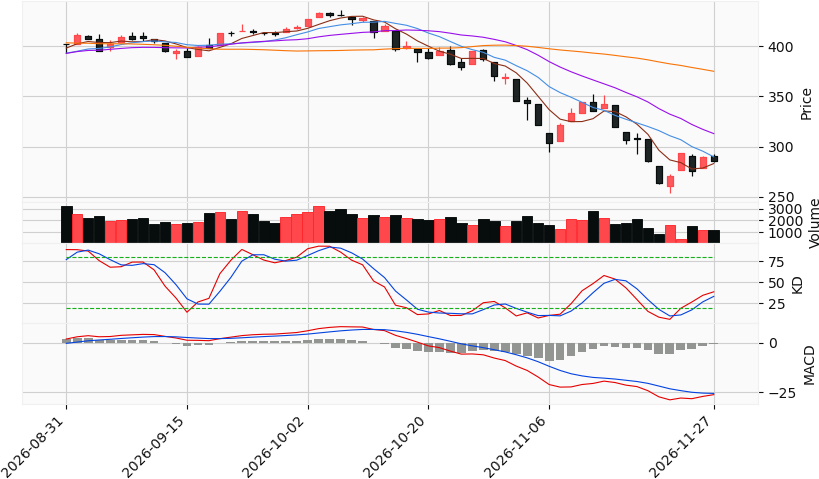

技術分析工具,解盤內容
Ｋ線／Ｋ棒,孕育線／懷抱線 : 2026-11-26
Ｋ線圖,中期為低位階 長期為低位階
成交量,價量關係：成交量小於十日均量（成交量 ＝ 1216.04億元 ，十日均量 ＝ 1379.37億元）
型態,反轉型態之上升楔形，型態範圍由2026-07-30開始到2026-10-08結束。 尚未成形底型反轉之底部型態，型態範圍由2026-11-03開始到2026-11-27結束。
移動平均線,5日線上揚、10日線下彎，短期盤整；20日線下彎、60日線下彎，中期翻空；120日線下彎、240日線上揚，長期盤整
ＫＤ指標,於2026-11-24黃金交叉。
ＭＡＣＤ指標,MACD雙線在零軸以下，中期空方
週Ｋ－週ＫＤ指標,於2026-11-09當週黃金交叉。並且2026-11-23該週在超賣區。
整體評價,價格趨勢 整體仍屬下跌趨勢：價格長時間位於中期均線之下，且中期均線持續下彎，顯示反彈仍偏屬跌勢中的修正。短線雖自低檔回升並站回短期均線附近，但尚未扭轉中期下行結構。 價量關係 近期反彈過程中，成交量呈現未明顯放大、偏震盪的型態，顯示追價動能仍較保守。若後續要有效突破上方壓力區，需觀察成交量是否能同步增加，否則較易出現衝高回檔或假突破。 支撐與壓力 - 支撐：先看近期回測低點約285點附近；若跌破，下一道支撐看前低區約271點附近。 - 壓力：上方先看短線反彈高點區約293點附近；再上去則為下彎的中期均線壓力帶約313點附近，屬較關鍵的反壓區。 KD 指標解讀 KD 自超賣區回升並維持向上，代表短線反彈動能仍在延續。惟目前仍在相對低檔區間，較偏向「跌深反彈」訊號，需搭配價格能否突破壓力區來確認轉強。 MACD 指標解讀 DIF 仍位於 MACD 線之下，整體仍屬偏空架構；但柱狀體負值明顯收斂，顯示空方動能正在減弱。若後續柱狀體能翻正並帶動 DIF 上穿 MACD 線，才較有利於形成較完整的趨勢反轉。 綜合評價 目前屬下跌趨勢中的反彈整理：空方動能降溫、短線技術面改善，但中期均線壓力仍重。操作上可把293點視為短線多空分界，能否帶量突破決定反彈延伸力道；若跌破285點，則需提防再度回檔測試271點支撐的風險。


In [5]:
# 盤後：櫃買指數解盤
stock_analysis(analysis,'TPEx')

* 驗證：宣德(5457)  

ＤＥＢＵＧ ： 日Ｋ開始日期 ＝ 2024-11-25 ，日Ｋ結束日期 ＝ 2026-11-28 ， 週Ｋ開始日期 ＝ 2024-11-25 ， 週Ｋ結束日期 ＝ 2026-11-23
ＤＥＢＵＧ ： 日Ｋ價格資料總數＝ 488
ＤＥＢＵＧ ： 轉折點引數列表 ＝ [{'mode': 'open_close', 'order': 5}, {'mode': 'open_close', 'order': 10}, {'mode': 'close', 'order': 10, 'smoothing': 3}]
ＤＥＢＵＧ ： 轉折點資料確認範圍 （開始索引 ＝ 0 ，結束索引 ＝ 29） 
ＤＥＢＵＧ ： ＃ 前轉折高點超過此轉折高點１０％，進行特別處理。前一轉折高點 ＝ 
Date     2026-07-07 00:00:00
Price                  34.95
Type                      HI
Name: 262, dtype: object
此轉折高點 ＝ 
Date     2026-08-10 00:00:00
Price                   28.8
Type                      HI
Name: 285, dtype: object
ＤＥＢＵＧ ： ＃ 前轉折高點超過此轉折高點１０％，進行特別處理。前一轉折高點 ＝ 
Date     2026-08-10 00:00:00
Price                   28.8
Type                      HI
Name: 285, dtype: object
此轉折高點 ＝ 
Date     2026-10-05 00:00:00
Price                   24.8
Type                      HI
Name: 323, dtype: object
ＤＥＢＵＧ ： 底部型態開始索引 ＝ 314 （日期 ＝ 2026-09-18 ） ， 底部型態結束索引 ＝ 354 （日期 ＝ 2026-11-20 ）
ＤＥＢＵＧ ： 趨勢線開始索引 ＝ 0（價格資料開始索引 ＝ 314），趨勢線結束索引 ＝ 40（價格資料結束索引 ＝ 354）
ＤＥＢＵＧ ： 底

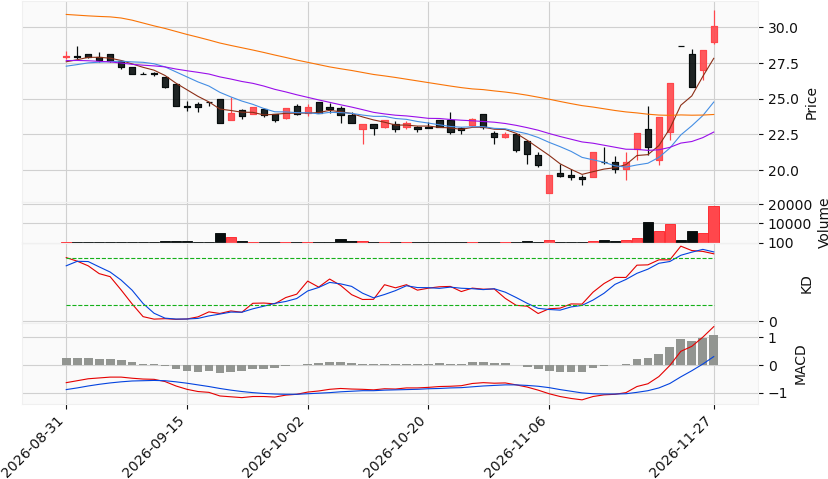

技術分析工具,解盤內容
Ｋ線／Ｋ棒,十字線 : 2026-11-24
Ｋ線圖,中期為高位階 長期為中位階
成交量,價量關係：中小型股大量／大型股天量（成交量 ＝ 19074張 ，十日均量 ＝ 6209張）
型態,反轉型態之下降楔形，型態範圍由2026-04-23開始到2026-11-18結束。
移動平均線,5日線上揚、10日線上揚，短期翻多；20日線上揚、60日線上揚，中期翻多；120日線下彎、240日線下彎，長期翻空
ＫＤ指標,於2026-11-26死亡交叉。並且2026-11-27於超買區。
ＭＡＣＤ指標,MACD雙線在零軸以上，中期多方
週Ｋ－週ＫＤ指標,於2026-09-28當週黃金交叉。
整體評價,價格趨勢 目前屬於上漲趨勢，近期以連續紅K推升並改寫波段高點，短線攻勢明顯。均線呈現短期均線上彎並站上中期均線，且價格明顯位於中期均線之上，趨勢偏多延續。 價量關係 上漲過程中成交量明顯放大，尤其最新一日放量長紅，屬於價漲量增的偏多結構，推升力道較具說服力。不過短線漲幅偏急，若後續再創高但量能未能同步維持，需留意高檔震盪與假突破風險。 支撐與壓力 - 壓力：先看前高附近約31.2元（上影線高點區），若帶量突破才有利續攻。 - 支撐：短線支撐先看約28.7元（近期大量區與回測位置），再來看約27.8元（短期均線附近）；若跌破，則轉看約25.9元（前低與整理區）作為較關鍵支撐。 KD 指標解讀 KD位於超買區上方，且K線略低於D線，顯示高檔動能有降溫跡象，短線較容易出現震盪或回檔。惟超買不宜單獨視為反轉訊號，仍需搭配價格是否跌破支撐與MACD動能是否轉弱來確認。 MACD 指標解讀 DIF位於MACD線之上且持續上行，柱狀體同步擴大，代表多方動能仍在增強，趨勢延續性偏正向。就目前圖形來看，尚未出現明顯的價格與MACD背離訊號。 綜合評價 整體為多頭強勢延續格局：均線轉多、MACD動能擴張、且放量上攻提高突破有效性。短線因KD處高檔且價格與短期均線乖離偏大，較可能以高檔震盪或回檔消化漲幅；操作上可重點觀察28.7元支撐是否守穩，以及挑戰31.2元時量能與MACD柱狀體是否續強。


In [6]:
stock_analysis(analysis,'5457')